This is a sample test of trying to load a simple video of my office and reconstruct a 3D image of it.

First we build s sharpness score function that returns the sharpness score of a frame.  This can be used to filter out frames that were too blurry.

In [ ]:
import cv2

def sharpness(frame, work_width = 960):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    scale = work_width / gray.shape[1]
    small = cv2.resize(gray, None, fix = scale, fy = scale, interpolation = cv2.INTER_AREA)
    return cv2.Laplacian(small, cv2.CV_64F).var()


This code block is to check the quality of images registered by the models built in Stage 1 under the run_sfm.py script.

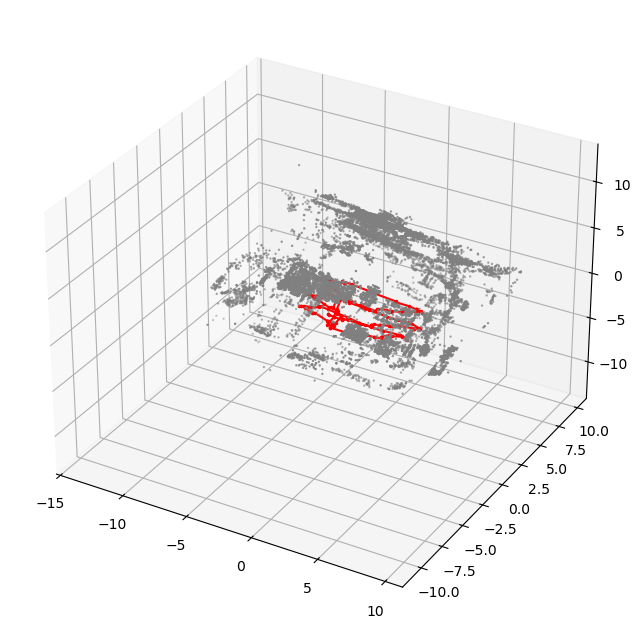

In [6]:
#!pip install pycolmap
import pycolmap
import numpy as np
import matplotlib.pyplot as plt

rec = pycolmap.Reconstruction('../data/colmap/office/sparse_best')
imgs = sorted(rec.images.values(), key = lambda im: im.name)
C = np.array([im.projection_center() for im in imgs])
P = np.array([p.xyz for p in rec.points3D.values()])

ax = plt.figure(figsize = (8,8)).add_subplot(projection = '3d')
ax.scatter(*P[::5].T, s = 0.5, c = 'gray')
ax.plot(*C.T, 'r.-', ms = 3)

plt.show()

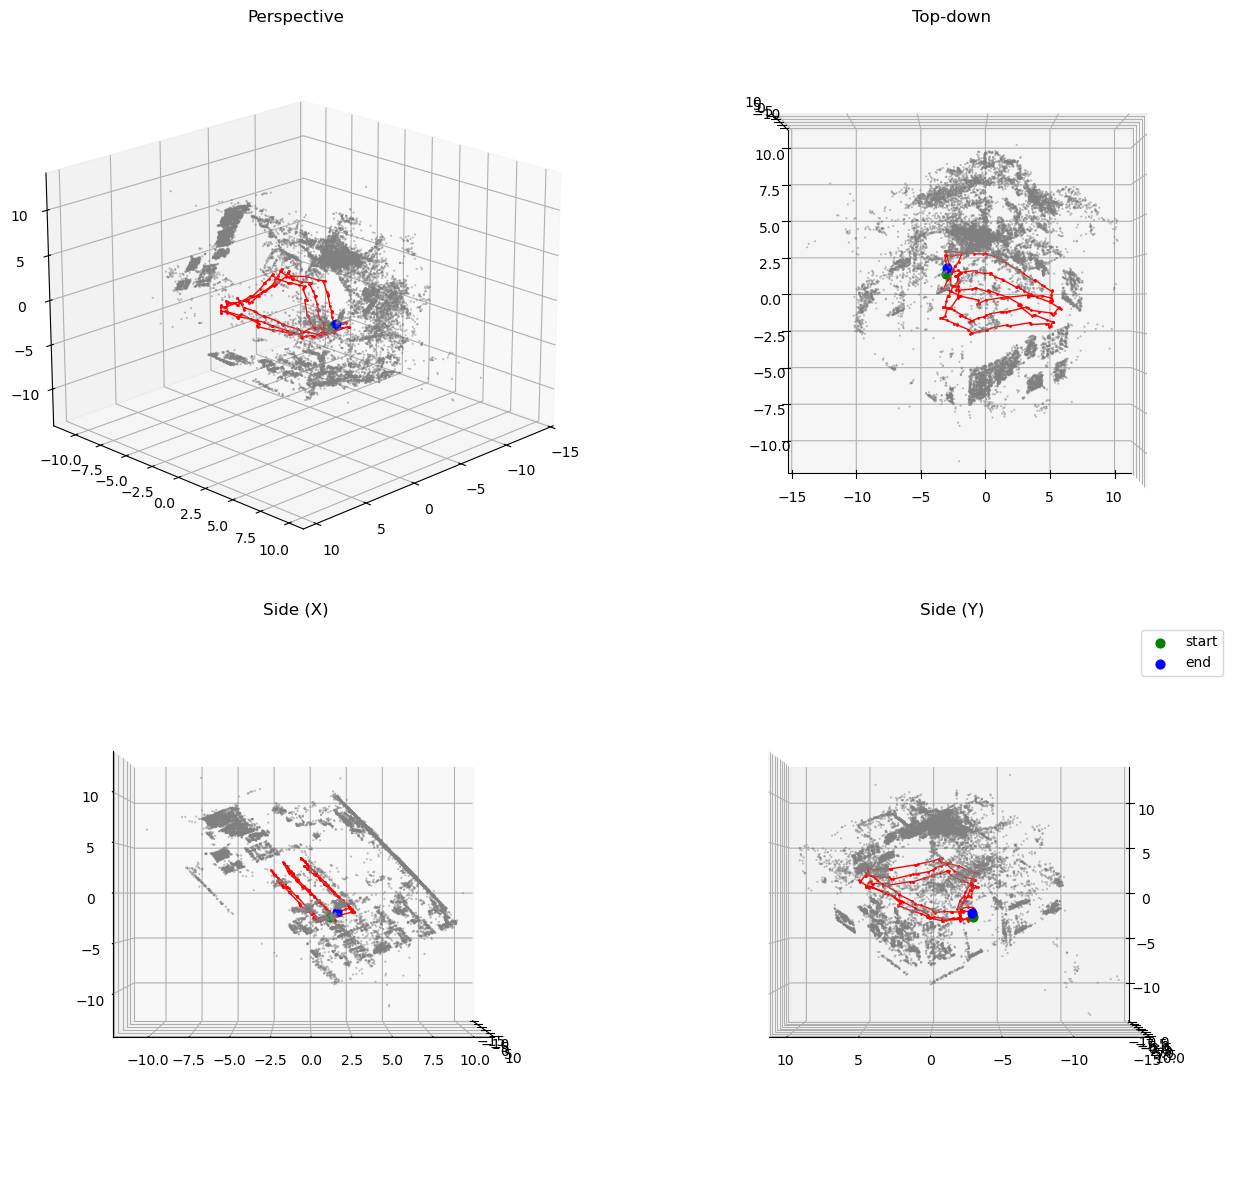

In [9]:
fig = plt.figure(figsize = (14, 12))
views = [(20, 45, 'Perspective'), (90, -90, 'Top-down'), (0, 0, 'Side (X)'), (0, 90, 'Side (Y)')]
for i, (elev, azim, title) in enumerate(views, 1):
    ax = fig.add_subplot(2, 2, i, projection = '3d')
    ax.scatter(*P[::5].T, s = 0.3, c = 'gray', alpha = 0.5)
    ax.plot(*C.T, 'r.-', ms = 2, lw = 1)
    ax.scatter(*C[0], c = 'green', s = 40, label = 'start')
    ax.scatter(*C[-1], c = 'blue', s = 40, label = 'end')
    ax.view_init(elev = elev, azim = azim)
    ax.set_title(title)
ax.legend()
plt.tight_layout()
plt.savefig('../data/colmap/office/camera_path.png', dpi = 120)
plt.show()